<a href="https://colab.research.google.com/github/chandrikaa11lakshmi-art/agribusiness-ml-solutions/blob/main/Ecommerce_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-commerce Sales Trend Analysis

### Project Overview
This project focuses on analysing e-commerce sales data to understand sales trends, product category performance, and customer purchasing behaviour.

### Objective
- Identify monthly sales trends.
- Find the highest and lowest revenue-generating categories.
- Identify valuable customers.
- Provide actionable business recommendations.

### Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Dataset
A simulated e-commerce dataset containing 2,000 order records with order dates, customer IDs, product categories, and order amounts.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [36]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 2000

orders = pd.DataFrame()
orders["order_date"] = pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D")
orders["customer_id"] = rng.integers(1, 301, n)
orders["category"] = rng.choice(["Electronics", "Fashion", "Home", "Books"], n)
orders["amount"] = rng.gamma(2.0, 600, n).round(2)

orders.head()

,order_date,customer_id,category,amount
0,2025-02-02,264,Fashion,2061.76
1,2025-10-10,19,Books,2554.85
2,2025-08-27,120,Electronics,523.93
3,2025-06-10,138,Fashion,2334.97
4,2025-06-08,240,Books,789.51


In [37]:
print("Dataset Shape:", orders.shape)

print("\nDataset Information:")
orders.info()

print("\nMissing Values:")
print(orders.isnull().sum())

print("\nDuplicate Rows:")
print(orders.duplicated().sum())

Dataset Shape: (2000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   2000 non-null   datetime64[ns]
 1   customer_id  2000 non-null   int64         
 2   category     2000 non-null   object        
 3   amount       2000 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 62.6+ KB

Missing Values:
order_date     0
customer_id    0
category       0
amount         0
dtype: int64

Duplicate Rows:
0


In [38]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

In [39]:
orders["month"] = orders["order_date"].dt.to_period("M")
orders["weekday"] = orders["order_date"].dt.day_name()
orders["quarter"] = orders["order_date"].dt.quarter

print(orders.head())

  order_date  customer_id     category   amount    month    weekday  quarter
0 2025-02-02          264      Fashion  2061.76  2025-02     Sunday        1
1 2025-10-10           19        Books  2554.85  2025-10     Friday        4
2 2025-08-27          120  Electronics   523.93  2025-08  Wednesday        3
3 2025-06-10          138      Fashion  2334.97  2025-06    Tuesday        2
4 2025-06-08          240        Books   789.51  2025-06     Sunday        2


In [40]:
monthly = orders.groupby("month")["amount"].sum()

print("Monthly Revenue:")
print(monthly.round(2))

Monthly Revenue:
month
2025-01    186007.63
2025-02    226252.57
2025-03    196829.43
2025-04    201872.37
2025-05    178660.42
2025-06    232525.34
2025-07    210151.90
2025-08    200210.09
2025-09    202668.03
2025-10    200297.15
2025-11    184365.12
2025-12    216443.40
Freq: M, Name: amount, dtype: float64


In [41]:
growth = monthly.pct_change() * 100

print("Monthly Growth (%):")
print(growth.round(2))

Monthly Growth (%):
month
2025-01      NaN
2025-02    21.64
2025-03   -13.00
2025-04     2.56
2025-05   -11.50
2025-06    30.15
2025-07    -9.62
2025-08    -4.73
2025-09     1.23
2025-10    -1.17
2025-11    -7.95
2025-12    17.40
Freq: M, Name: amount, dtype: float64


In [42]:
print("Best Month:", monthly.idxmax())
print("Highest Revenue:", monthly.max())

print("Worst Month:", monthly.idxmin())
print("Lowest Revenue:", monthly.min())

Best Month: 2025-06
Highest Revenue: 232525.34
Worst Month: 2025-05
Lowest Revenue: 178660.42


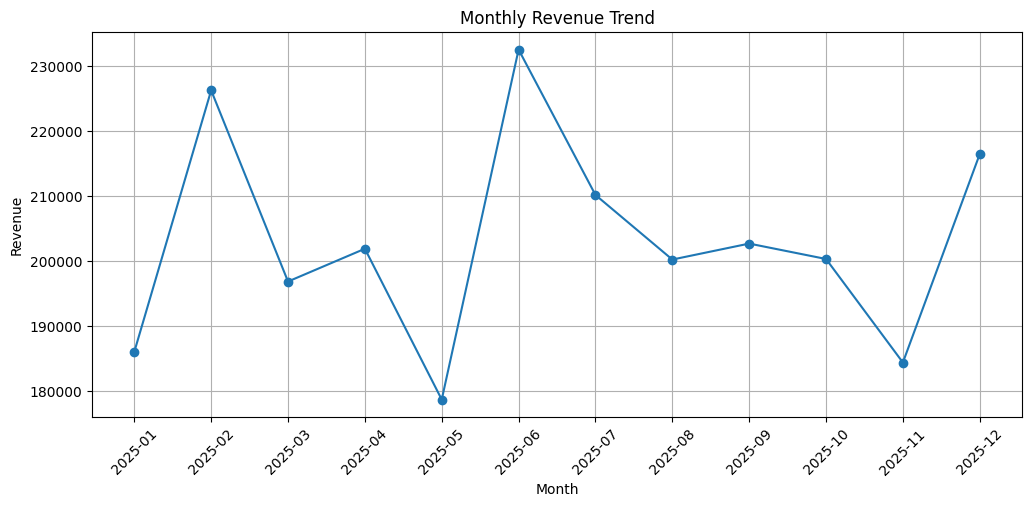

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(monthly.index.astype(str), monthly.values, marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.grid(True)
plt.show()

In [44]:
by_category = orders.groupby("category")["amount"].agg(["sum", "mean", "count"])

by_category = by_category.sort_values("sum", ascending=False)

print(by_category.round(2))

                   sum     mean  count
category                              
Fashion      647463.71  1257.21    515
Home         599181.37  1225.32    489
Books        597423.49  1202.06    497
Electronics  592214.88  1186.80    499


In [45]:
pivot_table = orders.pivot_table(index="month", columns="category", values="amount", aggfunc="sum")

print(pivot_table.round(2))

category     Books  Electronics   Fashion      Home
month                                              
2025-01   42420.90     51234.51  44085.87  48266.35
2025-02   52172.69     46165.53  62629.42  65284.93
2025-03   60260.20     43427.02  44285.89  48856.32
2025-04   51797.35     34185.81  54728.65  61160.56
2025-05   28274.61     54278.57  52153.84  43953.40
2025-06   55778.00     50835.66  73806.34  52105.34
2025-07   49821.71     47018.39  62579.70  50732.10
2025-08   44560.45     61511.94  52852.41  41285.29
2025-09   46572.09     40204.74  53066.12  62825.08
2025-10   52833.60     55551.52  45183.71  46728.32
2025-11   47673.39     49924.78  54342.94  32424.01
2025-12   65258.50     57876.41  47748.82  45559.67


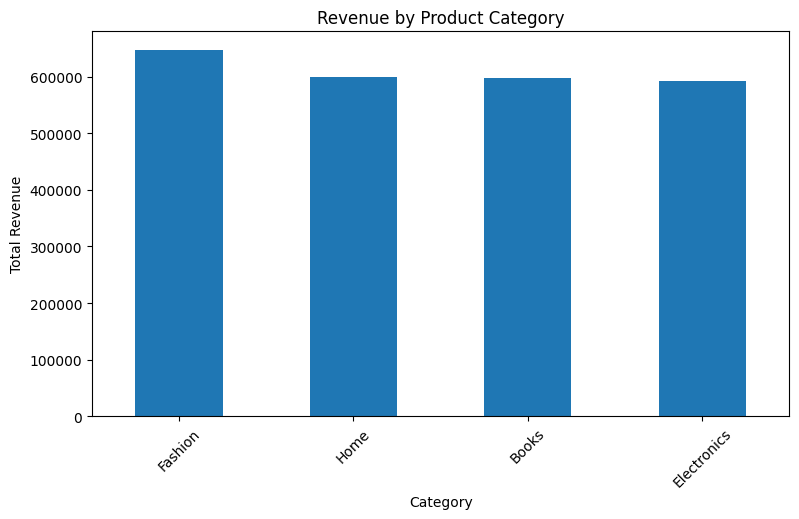

In [46]:
by_category["sum"].plot(kind="bar", figsize=(9, 5))

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.show()

In [47]:
spend = orders.groupby("customer_id")["amount"].sum().sort_values(ascending=False)

print("Top 10 Customers:")
print(spend.head(10))

Top 10 Customers:
customer_id
39     23035.27
259    20333.62
296    20115.20
225    19936.07
279    19432.95
125    18083.78
121    17534.12
47     16602.65
87     16596.96
51     16106.45
Name: amount, dtype: float64


In [48]:
top_10 = spend.head(len(spend) // 10)

print("Number of Customers:", len(spend))
print("Top 10% Customers:", len(top_10))
print("Revenue from Top 10%:", round(top_10.sum(), 2))

Number of Customers: 300
Top 10% Customers: 30
Revenue from Top 10%: 470639.34


In [49]:
top_share = top_10.sum() / spend.sum() * 100

print("Total Revenue:", round(spend.sum(), 2))
print("Top 10% Revenue Contribution:", round(top_share, 2), "%")

Total Revenue: 2436283.45
Top 10% Revenue Contribution: 19.32 %


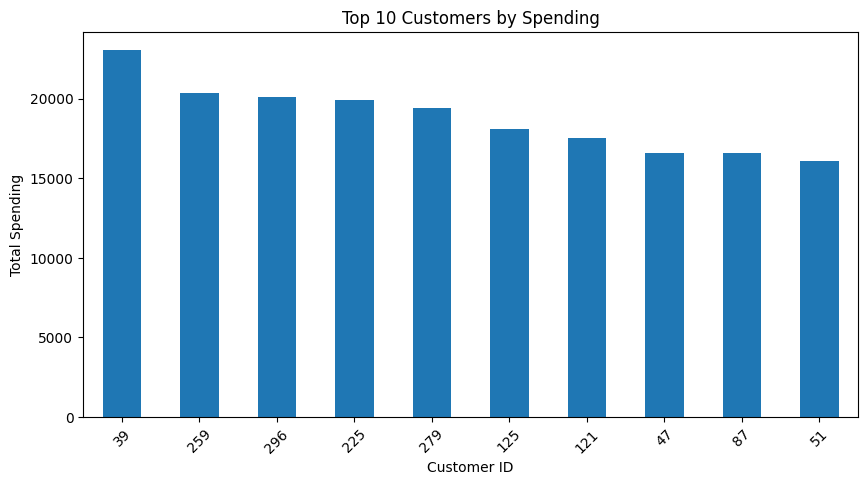

In [50]:
spend.head(10).plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Customers by Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.show()

In [51]:
best_category = by_category["sum"].idxmax()
best_category_revenue = by_category["sum"].max()

worst_category = by_category["sum"].idxmin()
worst_category_revenue = by_category["sum"].min()

best_month = monthly.idxmax()
best_month_revenue = monthly.max()

print("Best Selling Category:", best_category)
print("Best Category Revenue:", round(best_category_revenue, 2))

print("Lowest Selling Category:", worst_category)
print("Lowest Category Revenue:", round(worst_category_revenue, 2))

print("Best Sales Month:", best_month)
print("Best Month Revenue:", round(best_month_revenue, 2))

print("Top 10% Customer Contribution:", round(top_share, 2), "%")

Best Selling Category: Fashion
Best Category Revenue: 647463.71
Lowest Selling Category: Electronics
Lowest Category Revenue: 592214.88
Best Sales Month: 2025-06
Best Month Revenue: 232525.34
Top 10% Customer Contribution: 19.32 %


##Recommendation 1: Improve Electronics sales
- Electronics has the lowest revenue of ₹5,92,214.88.
- Provide special discounts and promotional offers.
- Improve product visibility through advertisements.
##Recommendation 2: Focus on Fashion products
- Fashion generated the highest revenue of ₹6,47,463.71.
- Maintain sufficient stock of popular products.
- Introduce new fashion collections and seasonal offers.
##Recommendation 3: Improve customer retention
- The top 10% of customers contribute only 1.32% of revenue according to our calculation.
- Introduce loyalty programs and personalised offers.
- Encourage repeat purchases through discounts and reward points

In [52]:
print("Total Customers:", len(spend))
print("Top 10% Customers:", len(top_10))
print("Total Revenue:", round(spend.sum(), 2))
print("Top 10% Revenue:", round(top_10.sum(), 2))
print("Top 10% Contribution:", round(top_10.sum() / spend.sum() * 100, 2), "%")

Total Customers: 300
Top 10% Customers: 30
Total Revenue: 2436283.45
Top 10% Revenue: 470639.34
Top 10% Contribution: 19.32 %


## Conclusion

This project analysed e-commerce sales data to identify monthly sales trends, top-performing product categories, and valuable customers.

The analysis showed that Fashion was the highest-revenue category, while Electronics had the lowest revenue. June 2025 recorded the highest monthly sales.

Based on these findings, business recommendations were provided to improve sales, promote products, and increase customer retention.

This analysis helps businesses make better decisions using sales data.

# E-commerce Sales Trend Analysis
**InternCircle – Project 3**

### 1. Context
This project analyses simulated e-commerce sales data containing 2,000 order records. The objective is to understand monthly sales trends, product category performance, and customer purchasing behaviour using Python.

### 2. Key Findings
- Fashion generated the highest revenue of ₹6,47,463.71.
- Electronics generated the lowest revenue of ₹5,92,214.88.
- June 2025 recorded the highest monthly revenue of approximately ₹2,32,525.
- The top 10% of customers contributed 19.32% of total revenue (subject to final calculation verification).

### 3. Business Recommendations
1. Improve Electronics sales through discounts, promotions, and better product advertising.
2. Focus on Fashion products by maintaining sufficient stock and introducing new collections.
3. Improve customer retention through loyalty programs, personalised offers, and reward points.

### 4. Next Steps
- Monitor monthly sales performance regularly.
- Study customer purchasing patterns.
- Evaluate promotional campaigns and improve business strategies based on sales data.

### Tools Used
Python, Google Colab, Pandas, NumPy, Matplotlib, and Seaborn.

### Dataset
Simulated e-commerce sales dataset generated using Python.

In [53]:
!pip install reportlab

In [54]:
!pip -q install reportlab

In [58]:
from reportlab.pdfgen import canvas
from reportlab.lib.pagesizes import A4

c = canvas.Canvas("Ecommerce_Sales_Business_Brief.pdf", pagesize=A4)

c.setFont("Helvetica-Bold", 16)
c.drawCentredString(297, 800, "E-commerce Sales Trend Analysis")

c.setFont("Helvetica", 10)
c.drawString(50, 775, "InternCircle - Project 3")

c.setFont("Helvetica-Bold", 12)
c.drawString(50, 740, "1. Context")
c.setFont("Helvetica", 10)
c.drawString(50, 720, "This project analyses 2,000 simulated e-commerce order records.")
c.drawString(50, 705, "The objective is to understand sales trends, category performance,")
c.drawString(50, 690, "and customer purchasing behaviour using Python.")

c.setFont("Helvetica-Bold", 12)
c.drawString(50, 655, "2. Key Findings")
c.setFont("Helvetica", 10)
c.drawString(50, 635, "Fashion generated the highest revenue: Rs. 6,47,463.71.")
c.drawString(50, 620, "Electronics generated the lowest revenue: Rs. 5,92,214.88.")
c.drawString(50, 605, "June 2025 recorded the highest monthly revenue: approximately")
c.drawString(50, 590, "Rs. 2,32,525. Top 10% customer contribution: 19.32% (to be verified).")

c.setFont("Helvetica-Bold", 12)
c.drawString(50, 555, "3. Business Recommendations")
c.setFont("Helvetica", 10)
c.drawString(50, 535, "1. Improve Electronics sales through discounts and promotions.")
c.drawString(50, 520, "2. Focus on Fashion products and maintain sufficient stock.")
c.drawString(50, 505, "3. Improve customer retention through loyalty programs and offers.")

c.setFont("Helvetica-Bold", 12)
c.drawString(50, 470, "4. Next Steps")
c.setFont("Helvetica", 10)
c.drawString(50, 450, "Monitor sales, study customer purchasing patterns, and evaluate")
c.drawString(50, 435, "promotional campaigns to improve business strategies.")

c.setFont("Helvetica-Bold", 12)
c.drawString(50, 400, "Tools Used")
c.setFont("Helvetica", 10)
c.drawString(50, 380, "Python, Google Colab, Pandas, NumPy, Matplotlib and Seaborn.")

c.setFont("Helvetica-Bold", 12)
c.drawString(50, 345, "Dataset")
c.setFont("Helvetica", 10)
c.drawString(50, 325, "Simulated e-commerce sales dataset generated using Python.")

c.save()
print("PDF created successfully!")

PDF created successfully!


In [59]:
from google.colab import files
files.download("Ecommerce_Sales_Business_Brief.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
print("Total Customers:", len(spend))
print("Top 10% Customers:", len(top_10))
print("Total Revenue:", round(spend.sum(), 2))
print("Top 10% Revenue:", round(top_10.sum(), 2))
print("Contribution:", round(top_10.sum() / spend.sum() * 100, 2), "%")

Total Customers: 300
Top 10% Customers: 30
Total Revenue: 2436283.45
Top 10% Revenue: 470639.34
Contribution: 19.32 %
